# Zehn Forschungsfragen an die Regensburger Flugblätter 1967–1973

Das Notebook liest den Export der App (*Verwaltung → Datensatz exportieren*, alle Bände, mit Namen), entpackt nach `data/export/flugblaetter-export/`.

Die Befunde beruhen auf dem Export vom 17.10.2026 (1 927 Exemplare, 1 547 Flugblätter, Themen mit den Titeln vom 14.10.2026). Ihre Zahlen sind von Hand übertragen. Nach einem neuen Export oder Themenlauf deshalb zuerst die Tabellen ansehen und die Befunde abgleichen. Jedes Flugblatt zählt einmal, mit seinem Hauptexemplar.

Für alle Fragen gilt:
- Titel, Datum, Herausgeber, Unterzeichnende und Thema hat ein Sprachmodell aus dem OCR-Text erzeugt. Von Hand geprüft ist nur ein kleiner Teil (Feld `korrigiert`).
- Die Sammlung ist kein Zufallsausschnitt. Einige Bände sind nach Gruppen sortiert (RCDS, AStA, Demokratische Front, siehe Frage 1).
- Mehr als die Hälfte der Flugblätter ist undatiert. Für Jahresvergleiche gilt deshalb das Datum, sonst der Eingangsstempel, sonst das Jahr des Bandes. Ein Dutzend Eingangsstempel ist falsch gelesen (1974–1978) und wird übergangen.

Die Fragen:
1. Wer spricht, und wie stark prägen die Sonderbände das Bild?
2. Welche Gruppen sind wann aktiv?
3. Wer gibt mit wem gemeinsam heraus?
4. Wer schreibt über wen?
5. Welche Themen besetzen die Gruppen?
6. Wie unterscheidet sich das Vokabular von RCDS und sozialistischen Gruppen?
7. Wie verläuft der Konflikt um das Bayerische Hochschulgesetz?
8. Wann im Jahr wird mobilisiert?
9. Wie international ist der Protest?
10. Wer unterschreibt, und für wen?

In [1]:
import re
from collections import Counter
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option('display.max_colwidth', 80)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

DATA = '../data/export/flugblaetter-export/'
alle = pd.read_json(DATA + 'flugblaetter.jsonl', lines=True)
personen = pd.read_csv(DATA + 'flugblatt_herausgeber.csv', dtype=str).fillna('')
register = pd.read_csv(DATA + 'herausgeber.csv', dtype=str).fillna('')
baende = pd.read_csv(DATA + 'baende.csv')

f = alle[(alle.hauptexemplar == '') | (alle.hauptexemplar == alle.id)].set_index('id')
band_jahr = baende.set_index('band').jahr
def jahr(datum, stempel, band):
    # ein Eingangsstempel, der mehr als ein Jahr vom Band abweicht, ist falsch gelesen (1978 statt 1972)
    if datum:
        return int(datum[:4])
    if stempel and abs(int(stempel[:4]) - band_jahr[band]) <= 1:
        return int(stempel[:4])
    return int(band_jahr[band])

f['jahr'] = [jahr(*z) for z in zip(f.datum, f.eingangsstempel, f.band)]
f['sonderband'] = f.band.map(baende.set_index('band').titel.str.contains(r'\. '))

# Herausgeber mit Register-ID; die übrigen (unter 2 %) stehen nicht im Register
hg = personen[(personen.rolle == 'herausgeber') & personen.flugblatt.isin(f.index) & (personen.herausgeber_id != '')]
name = register.set_index('id').name
print(f"{len(alle)} Flugblätter, davon {len(f)} ohne Duplikate; {(f.datum != '').mean():.0%} datiert; "
      f"{f.korrigiert.str.len().gt(0).mean():.0%} mit Korrekturen von Hand")

1927 Flugblätter, davon 1547 ohne Duplikate; 46% datiert; 3% mit Korrekturen von Hand


In [2]:
def heat(table, title, fmt='{:.0f}', cmap='Blues'):
    # table: DataFrame with numbers; one cell per value
    fig, ax = plt.subplots(figsize=(0.55 * table.shape[1] + 3, 0.35 * table.shape[0] + 1.5))
    ax.imshow(table.values, cmap=cmap, aspect='auto')
    ax.set_xticks(range(table.shape[1]), table.columns, rotation=60, ha='right')
    ax.set_yticks(range(table.shape[0]), table.index)
    top = np.nanmax(table.values) or 1
    for (i, j), v in np.ndenumerate(table.values):
        if v:
            ax.text(j, i, fmt.format(v), ha='center', va='center', fontsize=7, color='white' if v > top * 0.6 else 'black')
    ax.set_title(title, loc='left')
    plt.show()

GRUPPEN = ['asta', 'rcds', 'dm', 'als', 'msb', 'df', 'gew', 'shb', 'mhg', 'lsd', 'khb', 'sds', 'linke_liste', 'juso']
kurz = {g: register.set_index('id').name.get(g, g) for g in GRUPPEN}

## 1. Wer spricht, und wie stark prägen die Sonderbände das Bild?

Wer hat die meisten Flugblätter herausgegeben? Und wie ändert sich der Anteil, wenn man nur die allgemeinen Bände betrachtet, also ohne die nach Gruppen sortierten Sonderbände?

In [3]:
n = hg.drop_duplicates(['flugblatt', 'herausgeber_id']).merge(f[['sonderband']], left_on='flugblatt', right_index=True)
anteil = pd.DataFrame({
    'gesamt': n.herausgeber_id.value_counts(),
    'nur allgemeine Bände': n[~n.sonderband].herausgeber_id.value_counts(),
    'in Sonderbänden': n[n.sonderband].herausgeber_id.value_counts(),
}).fillna(0).astype(int).sort_values('gesamt', ascending=False).head(15)
anteil.index = anteil.index.map(lambda g: name.get(g, g))
for spalte, basis in (('gesamt', len(f)), ('nur allgemeine Bände', (~f.sonderband).sum())):
    anteil[f'% {spalte}'] = (anteil[spalte] / basis * 100).round(1)
anteil

,gesamt,nur allgemeine Bände,in Sonderbänden,% gesamt,% nur allgemeine Bände
herausgeber_id,,,,,
AStA,317,166,151,20.5,14.0
RCDS,133,39,94,8.6,3.3
DM,66,66,0,4.3,5.6
ALS,66,65,1,4.3,5.5
MSB,60,59,1,3.9,5.0
DF,55,5,50,3.6,0.4
Fachschaft Wirtschaftswissenschaft,54,52,2,3.5,4.4
GEW,33,31,2,2.1,2.6
MHG,30,30,0,1.9,2.5


In [4]:
oben = n.herausgeber_id.value_counts()
kumuliert = oben.cumsum() / len(f)
print(f"{(f.index.isin(hg.flugblatt)).mean():.0%} der Flugblätter haben einen erkannten Herausgeber, "
      f"{oben.size} verschiedene Herausgeber.")
print(f"Die {(kumuliert < 0.5).sum() + 1} häufigsten Herausgeber stehen auf der Hälfte aller Flugblätter.")

83% der Flugblätter haben einen erkannten Herausgeber, 170 verschiedene Herausgeber.
Die 8 häufigsten Herausgeber stehen auf der Hälfte aller Flugblätter.


**Befund.** Der AStA steht auf jedem fünften Flugblatt, danach folgt der RCDS. Die Rangfolge hängt aber an den Sonderbänden: 50 der 55 Flugblätter der Demokratischen Front und gut zwei Drittel der RCDS-Blätter (94 von 133) stammen aus Bänden, die nur diese Gruppe enthalten. In den allgemeinen Bänden fällt der RCDS von 8,6 % auf 3,3 % und liegt hinter Demokratischer Mitte, ALS, MSB und der Fachschaft Wirtschaftswissenschaft. Die DF kommt dort praktisch nicht vor. Die Zahlen hängen also auch davon ab, wer sein Material geschlossen ans Archiv gegeben hat. Für Vergleiche zwischen Gruppen eignen sich nur die allgemeinen Bände, oder man liest beide Spalten nebeneinander.

## 2. Welche Gruppen sind wann aktiv?

Flugblätter je Gruppe und Jahr. Für undatierte Blätter zählt der Eingangsstempel oder das Jahr des Bandes.

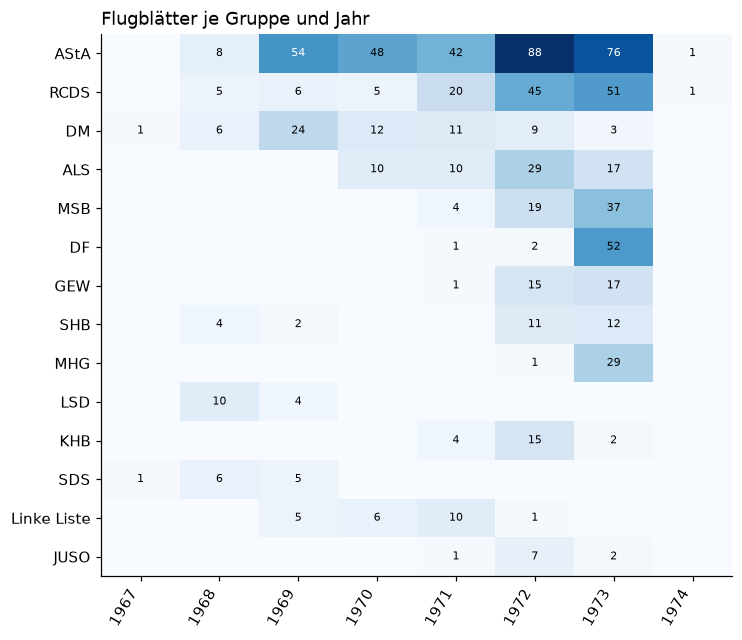

In [5]:
jahre = hg.drop_duplicates(['flugblatt', 'herausgeber_id']).merge(f[['jahr']], left_on='flugblatt', right_index=True)
tabelle = pd.crosstab(jahre.herausgeber_id, jahre.jahr).reindex(GRUPPEN).fillna(0)
tabelle.index = tabelle.index.map(kurz.get)
heat(tabelle, 'Flugblätter je Gruppe und Jahr')

**Befund.** Man sieht zwei Generationen. 1967–1969 sind SDS, LSD und SHB aktiv, dazu die Demokratische Mitte mit einem Schwerpunkt 1969. Der SDS verschwindet danach fast ganz, wie bundesweit nach seiner Auflösung 1970. Ab 1971/72 kommen die neuen Gruppen: MSB Spartakus, KHB, GEW, ab 1973 die MHG und die Demokratische Front. Die Linke Liste ist 1969–1971 aktiv und verschwindet dann. Die Jahre 1972 und 1973 sind mit je mehreren Bänden viel dichter gesammelt, die hohen Zahlen dort gehen vor allem darauf zurück. Für Trends sind Anteile pro Jahr besser (siehe Frage 9).

## 3. Wer gibt mit wem gemeinsam heraus?

Paare von Herausgebern auf demselben Flugblatt.

In [6]:
paare = Counter()
for _, gruppe in hg.groupby('flugblatt'):
    for a, b in combinations(sorted(set(gruppe.herausgeber_id) - {''}), 2):
        paare[a, b] += 1
mehrere = hg.groupby('flugblatt').herausgeber_id.nunique().gt(1).sum()
print(f"{mehrere} von {len(f)} Flugblättern ({mehrere / len(f):.0%}) haben mehr als einen Herausgeber.")
pd.DataFrame([(name.get(a, a), name.get(b, b), k) for (a, b), k in paare.most_common(20)],
             columns=['Herausgeber A', 'Herausgeber B', 'gemeinsame Flugblätter'])

66 von 1547 Flugblättern (4%) haben mehr als einen Herausgeber.


,Herausgeber A,Herausgeber B,gemeinsame Flugblätter
0,LSD,SDS,5
1,LSD,SHB,5
2,SDS,SHB,5
3,AStA,Linke (AStA-)Fraktion,5
4,AStA der Universität Würzburg,Universitätspresseamt Würzburg,4
5,LFS/LAF,Linke (AStA-)Fraktion,3
6,AStA,Fachschaften,3
7,JUSO,SHB,3
8,MAFAG,MHG,3
9,AStA,Rektor,2


**Befund.** Gemeinsame Flugblätter sind selten (4 %). Das deutlichste Bündnis ist das von LSD, SDS und SHB (je 5 gemeinsame Blätter) aus der Zeit der Notstandsgesetze 1968. Später tritt die Linke AStA-Fraktion mit Fachschaften und der Liste der Fachschaften (LFS/LAF) auf, die MHG mit ihrer Psychologie-Fachgruppe (MAFAG), die Jusos mit dem SHB. Für ein Netzwerk der Gruppen reichen die gemeinsamen Blätter nicht aus, mehr zeigen die Erwähnungen in Frage 4.

## 4. Wer schreibt über wen?

Erwähnt ein Flugblatt im Text eine andere Gruppe? Gesucht wird nach Kürzel und Namen, Erwähnungen der eigenen Gruppe zählen nicht. Die Zahl ist der Anteil der Flugblätter des Absenders (Zeile), die den Adressaten (Spalte) nennen.

*Grenzen*: Eine Erwähnung kann Zustimmung, Polemik oder bloße Information sein. Kürzel wie „DF“ oder „ALS“ können in OCR-Fehlern auch zufällig vorkommen.

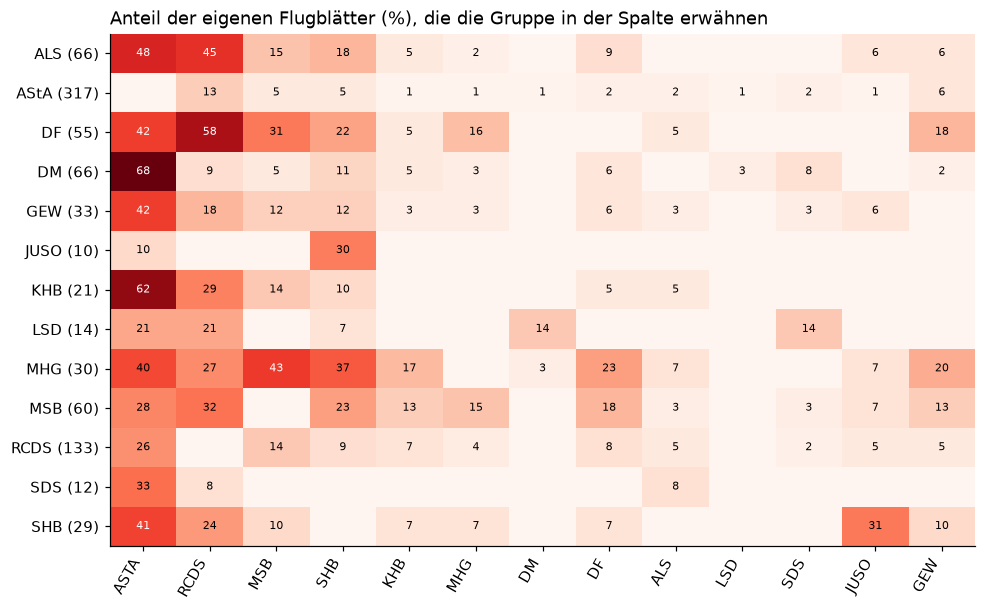

In [7]:
MUSTER = {
    'asta': r'\bAStA\b|\bASTA\b', 'rcds': r'\bRCDS\b', 'msb': r'\bMSB\b|Spartakus', 'shb': r'\bSHB\b',
    'khb': r'\bKHB\b', 'mhg': r'\bMHG\b', 'dm': r'Demokratischen? Mitte', 'df': r'Demokratischen? Front|\bDF\b',
    'als': r'\bALS\b', 'lsd': r'\bLSD\b', 'sds': r'\bSDS\b', 'juso': r'\bJusos?\b|Jungsozialist', 'gew': r'\bGEW\b',
}
eigene = hg.groupby('flugblatt').herausgeber_id.apply(set)
treffer = []
for fid, text in f.text.items():
    absender = eigene.get(fid, set()) & set(MUSTER)
    for ziel, muster in MUSTER.items():
        if absender and ziel not in absender and re.search(muster, text):
            treffer += [(a, ziel) for a in absender]
matrix = pd.crosstab(*zip(*treffer)).reindex(index=MUSTER, columns=MUSTER).fillna(0)
basis = hg[hg.herausgeber_id.isin(MUSTER)].drop_duplicates(['flugblatt', 'herausgeber_id']).herausgeber_id.value_counts()
prozent = (matrix.div(basis, axis=0) * 100).round()
prozent.index = [f"{kurz.get(g, g)} ({basis.get(g, 0)})" for g in prozent.index]
prozent.columns = [g.upper() for g in prozent.columns]
heat(prozent, 'Anteil der eigenen Flugblätter (%), die die Gruppe in der Spalte erwähnen', cmap='Reds')

In [8]:
# wer wird insgesamt am meisten von anderen erwähnt?
pd.DataFrame({'erwähnt von Flugblättern anderer Gruppen': matrix.sum().astype(int),
              'erwähnt selbst andere': matrix.sum(axis=1).astype(int)}).rename(index=kurz).sort_values(
    'erwähnt von Flugblättern anderer Gruppen', ascending=False)

,erwähnt von Flugblättern anderer Gruppen,erwähnt selbst andere
AStA,210,131
RCDS,160,110
SHB,94,40
MSB,88,94
GEW,58,36
DF,51,109
KHB,36,26
MHG,33,67
JUSO,31,4
ALS,21,102


**Befund.** Der AStA ist der Bezugspunkt fast aller Gruppen: Die Demokratische Mitte (68 %) und der KHB (62 %) nennen ihn in der Mehrzahl ihrer Blätter, die ALS in knapp der Hälfte (48 %). Gestritten wurde darum, wer den AStA stellt und was er darf. Am zweithäufigsten genannt wird der RCDS, vor allem von der Demokratischen Front (58 %) und der ALS (45 %). Die MHG schreibt am häufigsten über andere linke Gruppen (MSB 43 %, SHB 37 %), was auf Konkurrenz innerhalb der Linken hindeutet. Jusos und SHB nennen sich gegenseitig und geben auch gemeinsam heraus (Frage 3). Ob eine Erwähnung freundlich oder feindlich ist, zeigen erst die Fundstellen. In der App findet man sie, indem man das Kürzel sucht und nach Herausgeber filtert.

## 5. Welche Themen besetzen die Gruppen?

Die Themen stammen aus dem Topic Modelling. Erstens: Wie verteilen sich die Flugblätter einer Gruppe auf die Themen? Zweitens: Welche Themen gehören fast nur einer Gruppe?

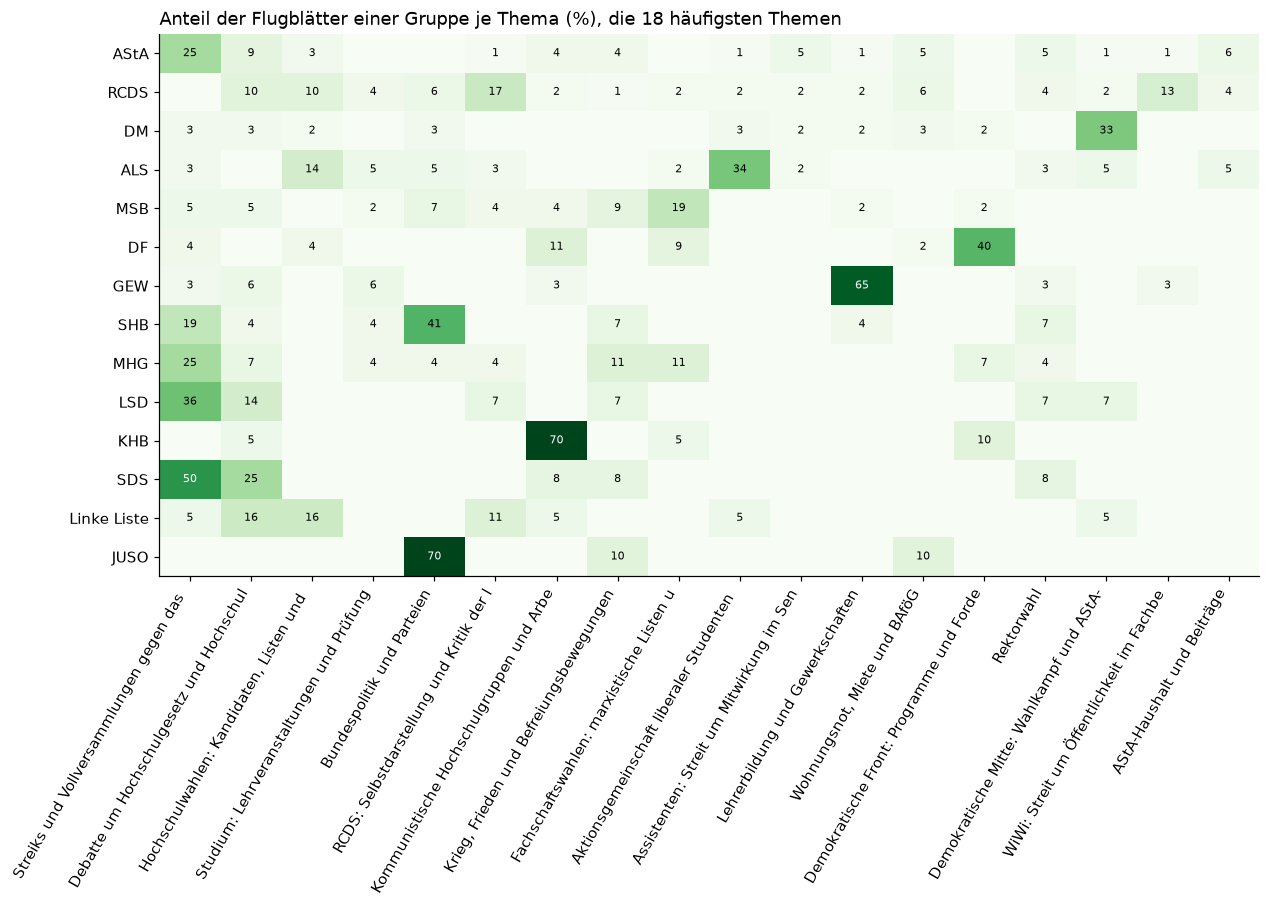

In [9]:
thema = hg.drop_duplicates(['flugblatt', 'herausgeber_id']).merge(f[['thema']], left_on='flugblatt', right_index=True)
thema = thema[thema.thema != '']
top_themen = f.thema[f.thema != ''].value_counts().head(18).index
tabelle = (pd.crosstab(thema.herausgeber_id, thema.thema, normalize='index') * 100).reindex(index=GRUPPEN, columns=top_themen).fillna(0)
tabelle.index = tabelle.index.map(kurz.get)
tabelle.columns = [t[:40] for t in tabelle.columns]
heat(tabelle.round(), 'Anteil der Flugblätter einer Gruppe je Thema (%), die 18 häufigsten Themen', cmap='Greens')

In [10]:
# Themen, die eine Gruppe dominiert: Anteil der größten Gruppe an den Flugblättern des Themas
zeilen = []
for t, gruppe in thema.groupby('thema'):
    zahlen = gruppe.herausgeber_id.value_counts()
    gesamt = gruppe.flugblatt.nunique()
    if gesamt >= 15:
        zeilen.append((t, gesamt, name.get(zahlen.index[0], zahlen.index[0]), round(zahlen.iloc[0] / gesamt * 100)))
pd.DataFrame(zeilen, columns=['Thema', 'Flugblätter', 'häufigste Gruppe', '% der Flugblätter']).sort_values(
    '% der Flugblätter', ascending=False).head(15)

,Thema,Flugblätter,häufigste Gruppe,% der Flugblätter
11,Demokratisierung der Hochschule: Positionen des RCDS,16,RCDS,75
16,Germanistik: Streit um Stellenbesetzung,16,Fachschaft Sprach- und Literaturwissenschaft,75
0,AStA-Haushalt und Beiträge,27,AStA,63
10,Demokratische Mitte: Wahlkampf und AStA-Konflikte,34,DM,62
30,VDS-Beitritt: Urabstimmung,18,DM,61
15,Fahrpreiserhöhungen im Nahverkehr,19,AStA,58
2,Aktionsgemeinschaft liberaler Studenten (ALS),38,ALS,58
8,Demokratische Front: Programme und Forderungen,37,DF,57
28,Streiks und Vollversammlungen gegen das Hochschulgesetz,135,AStA,56
27,Rektorwahl,27,AStA,56


**Befund.** Mehrere Themen hat das Topic Modelling um einen Absender herum gebildet. Von DF (40 %), ALS (34 %) und DM (33 %) fällt ein großer Teil der Blätter in das Thema, das nach der Gruppe benannt ist, beim KHB sind es 70 % in „Kommunistische Hochschulgruppen und Arbeiterbewegung“, beim RCDS 17 % in „RCDS: Selbstdarstellung und Kritik der linken Gruppen“. Solche Themen stehen eher für die Gruppe als für einen Inhalt. Deutliche inhaltliche Profile haben andere: Die GEW schreibt zu 65 % über Lehrerbildung, SHB (41 %) und Jusos (70 %, nur 10 Blätter) über „Bundespolitik und Parteien“, der RCDS häufiger als andere über die Öffentlichkeit im Fachbereichsrat WiWi. „Streiks und Vollversammlungen gegen das Hochschulgesetz“ ist das größte Thema (135 Blätter) und auf viele Gruppen verteilt, der AStA stellt etwas mehr als die Hälfte (56 %). Wer untersuchen will, welche Gruppe welches Thema besetzt, sollte die um Absender gebildeten Themen herausnehmen.

## 6. Wie unterscheidet sich das Vokabular von RCDS und sozialistischen Gruppen?

Vergleich der Wortwahl mit gewichteten Log-Odds (Monroe, Colaresi & Quinn 2008, „Fightin' Words“). Das Verfahren bevorzugt Wörter, die bei einer Seite deutlich häufiger sind, und dämpft seltene Wörter.
Verglichen wird der RCDS mit MSB Spartakus, SHB, KHB und MHG zusammen.

In [11]:
STOPP = set('''aber alle allem allen aller alles also auch auf aus bei beim bereits bis bisher dabei dadurch dafür dagegen daher damit dann
darauf daran darüber das dass daß dem den denen denn der deren des deshalb dessen die dies diese diesem diesen dieser dieses doch dort durch
eine einem einen einer eines einige einmal etwa euch fast für gegen geht gibt habe haben hat hatte hatten heute hier hinter ihre ihrem ihren
ihrer ihres immer jede jedem jeden jeder jedoch jetzt kann keine keinen können könnte mehr muss muß müssen nach nicht nichts noch nun nur oder
ohne schon sehr sein seine seinem seinen seiner selbst sich sie sind soll sollen sondern sowie über ueber unter uns unsere unserer unseren
viel vielen vom von vor wann war waren warum was weil weiter welche welcher wenn werden wieder will wir wird wo wollen worden wurde wurden zum
zur zwar zwischen sowohl allein dieser ebenfalls dazu wäre wären wollen würde würden somit beim''' .split())
# die Namen der verglichenen Gruppen selbst
STOPP |= {'rcds', 'ring', 'christlich', 'info', 'spartakus', 'msb', 'shb', 'khb', 'mhg', 'marxistische', 'marxistischen',
          'hochschulbund', 'sozialistischer', 'kommunistischer', 'studentenbund', 'hochschulgruppe'}

def woerter(texte):
    c = Counter()
    for t in texte:
        c.update(w for w in re.findall(r'[a-zäöüß]{4,}', t.lower()) if w not in STOPP)
    return c

def fightin_words(a, b, prior=0.01, n=20):
    alles = a + b
    vokabular = [w for w, k in alles.items() if k >= 10]
    a0, b0 = sum(a.values()), sum(b.values())
    alpha = {w: alles[w] * prior for w in vokabular}
    alpha0 = sum(alpha.values())
    z = {}
    for w in vokabular:
        la = np.log((a[w] + alpha[w]) / (a0 + alpha0 - a[w] - alpha[w]))
        lb = np.log((b[w] + alpha[w]) / (b0 + alpha0 - b[w] - alpha[w]))
        z[w] = (la - lb) / np.sqrt(1 / (a[w] + alpha[w]) + 1 / (b[w] + alpha[w]))
    z = pd.Series(z).sort_values()
    return pd.DataFrame({'typisch für Seite A': z.index[::-1][:n], 'z A': z.values[::-1][:n].round(1),
                         'typisch für Seite B': z.index[:n], 'z B': z.values[:n].round(1)})

def texte_von(gruppen):
    ids = hg[hg.herausgeber_id.isin(gruppen)].flugblatt.unique()
    return f.loc[ids, 'text']

rcds = texte_von(['rcds'])
sozialistisch = texte_von(['msb', 'shb', 'khb', 'mhg'])
print(f"A = RCDS ({len(rcds)} Flugblätter), B = MSB/SHB/KHB/MHG ({len(sozialistisch)} Flugblätter)")
fightin_words(woerter(rcds), woerter(sozialistisch))

A = RCDS (133 Flugblätter), B = MSB/SHB/KHB/MHG (138 Flugblätter)


,typisch für Seite A,z A,typisch für Seite B,z B
0,universität,7.0,kampf,-11.5
1,jura,5.6,politik,-8.2
2,kuhn,5.1,asta,-7.5
3,josef,4.9,demokratischen,-6.9
4,senat,4.7,kräfte,-6.3
5,karl,4.5,juso,-5.9
6,herr,4.4,maier,-5.9
7,obermair,4.4,demokratische,-5.8
8,informationen,4.3,fachschaften,-5.7
9,einzelnen,4.2,rechte,-5.7


**Befund.** Auf der sozialistischen Seite stehen Kampf, Politik, Kräfte, Reaktion, Arbeiterklasse, Bevölkerung und Streik, dazu der Kultusminister Hans Maier („Maier“, „Kumi“) als Gegner. Diese Sprache ordnet die Hochschule in einen gesellschaftlichen Konflikt ein. Der RCDS spricht über Universität, Jura, Senat, Lehre und Stellungnahme, also über Gremien und Studium, in höflicher Anrede („Herr“) und mit Bezug auf Eltern. Unter den typischen RCDS-Wörtern sind auch Namen von Unterzeichnern (Kuhn, Karl, Obermair). Die gleiche Funktion lässt sich für jedes andere Paar aufrufen, zum Beispiel `fightin_words(woerter(texte_von(['dm'])), woerter(texte_von(['df'])))`.

*Grenzen*: OCR-Fehler erzeugen seltene Kunstwörter, die die Mindesthäufigkeit von 10 aber meist herausfiltert. Lange Broschüren zählen stärker als kurze Blätter.

## 7. Wie verläuft der Konflikt um das Bayerische Hochschulgesetz?

Flugblätter, die das Hochschulgesetz (BHG) oder das Hochschulrahmengesetz (HRG) erwähnen, nach Monat. Nur Flugblätter mit Monatsangabe.

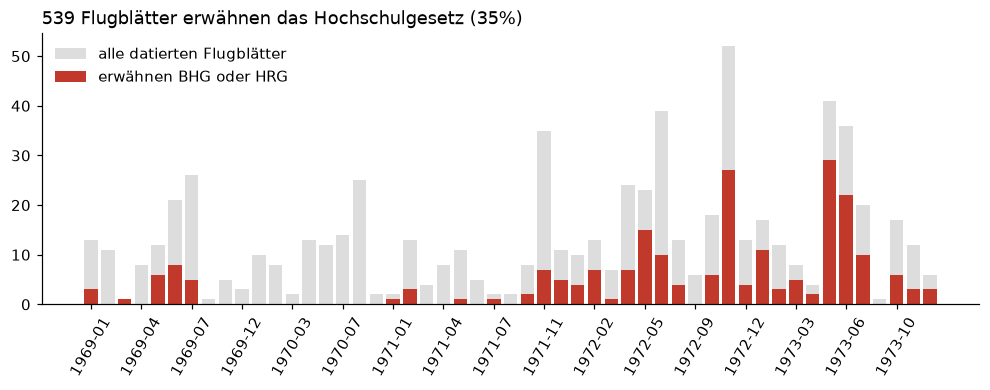

In [12]:
bhg = f[f.text.str.contains(r'Hochschulgesetz|\bBHG\b|Hochschulrahmengesetz|\bHRG\b')]
monat = bhg[bhg.datum.str.len() >= 7].datum.str[:7]
alle_monate = f[f.datum.str.len() >= 7].datum.str[:7].value_counts().sort_index()
reihe = pd.DataFrame({'BHG/HRG': monat.value_counts(), 'alle datierten': alle_monate}).fillna(0).loc['1969-01':]
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(reihe.index, reihe['alle datierten'], color='#ddd', label='alle datierten Flugblätter')
ax.bar(reihe.index, reihe['BHG/HRG'], color='#c0392b', label='erwähnen BHG oder HRG')
ax.set_xticks(range(0, len(reihe), 3), reihe.index[::3], rotation=60)
ax.legend(frameon=False)
ax.set_title(f"{len(bhg)} Flugblätter erwähnen das Hochschulgesetz ({len(bhg) / len(f):.0%})", loc='left')
plt.show()

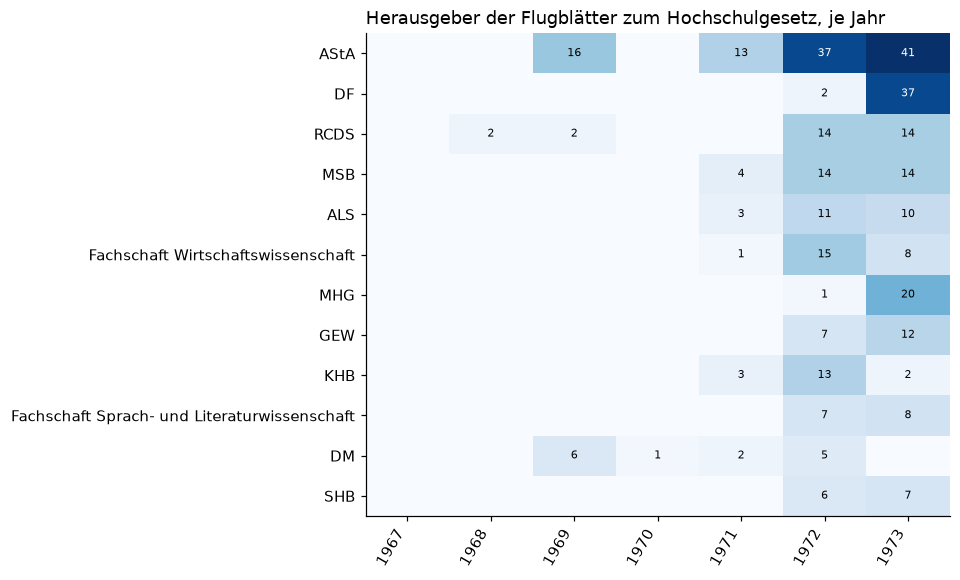

In [13]:
# wer schrieb wann darüber: Herausgeber der BHG-Flugblätter je Jahr
wer = hg[hg.flugblatt.isin(bhg.index)].drop_duplicates(['flugblatt', 'herausgeber_id']).merge(f[['jahr']], left_on='flugblatt', right_index=True)
tabelle = pd.crosstab(wer.herausgeber_id, wer.jahr)
tabelle = tabelle.loc[tabelle.sum(axis=1).sort_values(ascending=False).index[:12]]
tabelle.index = tabelle.index.map(lambda g: name.get(g, g))
heat(tabelle, 'Herausgeber der Flugblätter zum Hochschulgesetz, je Jahr')

**Befund.** Gut ein Drittel aller Flugblätter erwähnt das Hochschulgesetz (539 von 1 547). Nach einer ersten Welle im Sommer 1969 ist das Thema 1970 fast verschwunden. Ab November 1971 kommt es zurück, mit Spitzen im Mai 1972, im November 1972 (27 von 52 datierten Blättern des Monats) und im Mai/Juni 1973, als zwei Drittel der Blätter es nennen. Bis 1971 schreibt vor allem der AStA darüber. 1972/73 beteiligen sich fast alle Gruppen, 1973 neben dem AStA vor allem die Demokratische Front und die MHG. Zum Prüfen: in der App nach „BHG“ suchen und die Fundstellen-Ansicht öffnen.

## 8. Wann im Jahr wird mobilisiert?

Datierte Flugblätter nach Monat (Vorlesungszeiten damals ungefähr: Sommersemester Mai–Juli, Wintersemester November–Februar) und Wochentage der angekündigten Veranstaltungen.

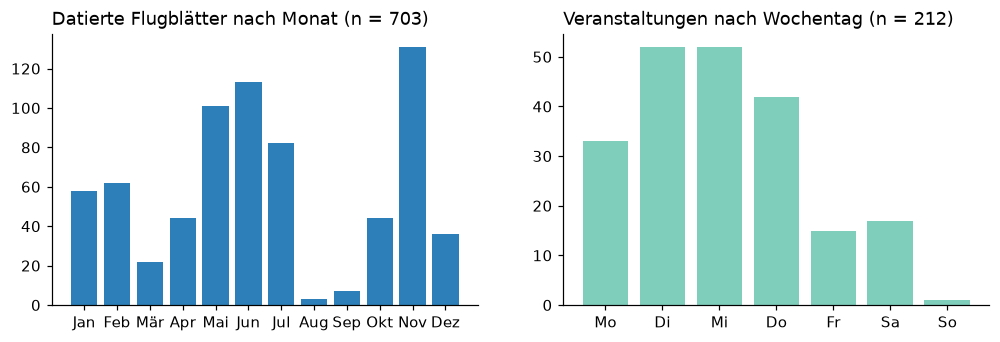

In [14]:
datiert = f[f.datum.str.len() >= 7]
monate = datiert.datum.str[5:7].astype(int).value_counts().reindex(range(1, 13), fill_value=0)
veranstaltung = f[(f.datumsart == 'event') & (f.datum.str.len() == 10)]
tage = pd.to_datetime(veranstaltung.datum, errors='coerce').dt.dayofweek.value_counts().reindex(range(7), fill_value=0)

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.2))
a.bar(['Jan', 'Feb', 'Mär', 'Apr', 'Mai', 'Jun', 'Jul', 'Aug', 'Sep', 'Okt', 'Nov', 'Dez'], monate.values, color='#2c7fb8')
a.set_title(f'Datierte Flugblätter nach Monat (n = {len(datiert)})', loc='left')
b.bar(['Mo', 'Di', 'Mi', 'Do', 'Fr', 'Sa', 'So'], tage.values, color='#7fcdbb')
b.set_title(f'Veranstaltungen nach Wochentag (n = {int(tage.sum())})', loc='left')
plt.show()

**Befund.** Flugblätter folgen dem Semester. August und September sind fast leer (3 und 7 datierte Blätter), der März ist schwach (22). Spitzen liegen im Mai bis Juli und im November. Der November ist der Monat nach Semesterbeginn, in dem gewählt wurde und 1972 der Streik gegen das Hochschulgesetz lief. Veranstaltungen liegen fast nur von Montag bis Donnerstag, am meisten am Dienstag und Mittwoch. Freitag und Wochenende fallen deutlich ab. Das spricht für eine Pendleruniversität, deren Studierende am Wochenende nicht in Regensburg waren. Das Datum kommt aus dem Text. Bei Flugblättern ohne Jahr hat das Sprachmodell das Jahr mitunter ergänzt, der Wochentag kann dann falsch sein.

## 9. Wie international ist der Protest?

Anteil der Flugblätter eines Jahres, die bestimmte Länder oder Konflikte nennen. Gesucht wird mit einfachen Wortlisten, auch Adjektive („vietnamesisch“) zählen.

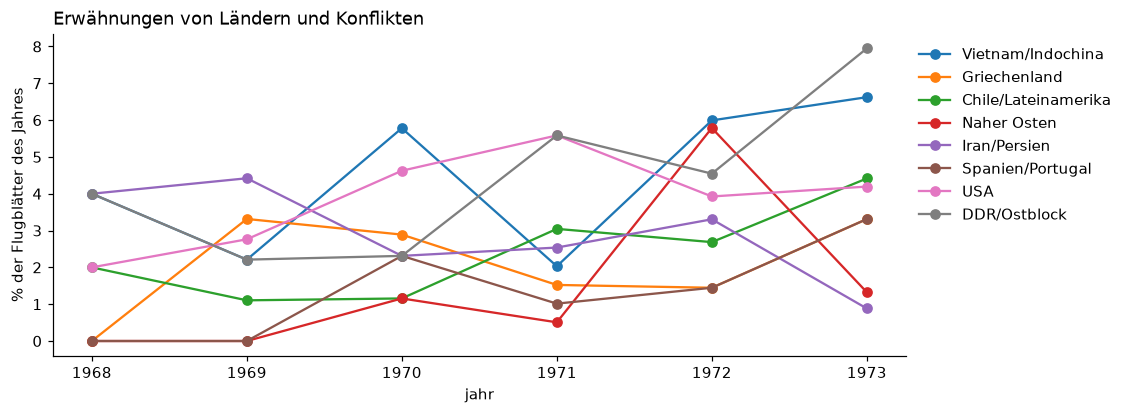

,Vietnam/Indochina,Griechenland,Chile/Lateinamerika,Naher Osten,Iran/Persien,Spanien/Portugal,USA,DDR/Ostblock
jahr,,,,,,,,
1968,4.0,0.0,2.0,0.0,4.0,0.0,2.0,4.0
1969,2.2,3.3,1.1,0.0,4.4,0.0,2.8,2.2
1970,5.8,2.9,1.2,1.2,2.3,2.3,4.6,2.3
1971,2.0,1.5,3.0,0.5,2.5,1.0,5.6,5.6
1972,6.0,1.4,2.7,5.8,3.3,1.4,3.9,4.5
1973,6.6,3.3,4.4,1.3,0.9,3.3,4.2,7.9


In [15]:
REGIONEN = {
    'Vietnam/Indochina': r'vietnam|indochina|kambodscha|\blaos\b|saigon|hanoi',
    'Griechenland': r'griechen|athen\b|junta',
    'Chile/Lateinamerika': r'chile|allende|lateinamerika|brasilien|bolivien',
    'Naher Osten': r'israel|paläst|palaest|nahost|arabisch|\bplo\b',
    'Iran/Persien': r'\biran|persien|persisch|schah\b',
    'Spanien/Portugal': r'spanien|\bfranco\b|portugal|angola|mosambik|moçambique|mozambique',
    'USA': r'\busa\b|amerikanisch|vereinigten staaten|nixon',
    'DDR/Ostblock': r'\bddr\b|sowjet|udssr|tschechoslowak|\bprag\b',
}
klein = f.text.str.lower()
anteile = pd.DataFrame({r: klein.str.contains(m).groupby(f.jahr).mean() * 100 for r, m in REGIONEN.items()})
anteile = anteile.loc[1968:1973]
fig, ax = plt.subplots(figsize=(10, 3.8))
anteile.plot(ax=ax, marker='o')
ax.set_ylabel('% der Flugblätter des Jahres')
ax.legend(frameon=False, bbox_to_anchor=(1, 1))
ax.set_title('Erwähnungen von Ländern und Konflikten', loc='left')
plt.show()
anteile.round(1)

**Befund.** Internationale Bezüge sind eine Minderheit: Keine Region erreicht in einem Jahr 8 % der Flugblätter, das Hochschulgesetz allein 34 % (Frage 7). Vietnam ist der beständigste Bezug und steigt bis 1973 auf gut 6 %. Der Nahe Osten hat eine einzelne Spitze 1972, in der Zeit nach dem Olympia-Attentat in München, als die Generalunion Palästinensischer Studenten verboten und arabische Studierende ausgewiesen wurden. Chile nimmt 1973 zu (Putsch im September). Die Erwähnungen von DDR und Ostblock betreffen Verschiedenes (Ostpolitik, Bundestagswahl 1972, Abrüstung) und bilden kein einheitliches Thema. Griechenland ist insgesamt selten (37 Flugblätter), am häufigsten erwähnt es der AStA. Weil 1967 und 1968 nur wenige Flugblätter überliefert sind, schwanken die Anteile dort stark.

## 10. Wer unterschreibt, und für wen?

Unterzeichnende haben keine Register-ID. Das Notebook fasst sie deshalb über den Nachnamen zusammen. Das trennt Personen mit gleichem Nachnamen nicht („Schmid“), führt aber „A. Karl“ und „Alois Karl“ zusammen.

*Datenschutz*: Das sind Namen von Studierenden der 1970er Jahre. Für eine Veröffentlichung reicht in der Regel die Auswertung nach Funktionen oder Gruppen.

In [16]:
unter = personen[(personen.rolle == 'unterzeichnend') & personen.flugblatt.isin(f.index)].copy()
unter['nachname'] = unter.name.str.replace(r'[.,]', ' ', regex=True).str.split().str[-1]
mit_gruppe = unter.merge(hg[['flugblatt', 'herausgeber_id']].rename(columns={'herausgeber_id': 'gruppe'}), on='flugblatt', how='left')
print(f"{unter.flugblatt.nunique()} Flugblätter ({unter.flugblatt.nunique() / len(f):.0%}) nennen Unterzeichnende; "
      f"{unter.nachname.nunique()} verschiedene Nachnamen.")
uebersicht = mit_gruppe.groupby('nachname').agg(
    flugblaetter=('flugblatt', 'nunique'),
    gruppen=('gruppe', lambda g: ', '.join(sorted({name.get(x, x) for x in g.dropna() if x})[:4])),
    anzahl_gruppen=('gruppe', lambda g: g.dropna().nunique()),
    jahre=('flugblatt', lambda ids: '–'.join(map(str, sorted({f.jahr[i] for i in ids})[::max(1, len({f.jahr[i] for i in ids}) - 1)]))),
    funktion=('funktion', lambda s: next((x for x in s if x), '')),
).sort_values('flugblaetter', ascending=False)
uebersicht.head(15)

696 Flugblätter (45%) nennen Unterzeichnende; 581 verschiedene Nachnamen.


,flugblaetter,gruppen,anzahl_gruppen,jahre,funktion
nachname,,,,,
Karl,50,"ALS, Fachschaft Soziologie-Politologie-Sozialkunde, MSB, RCDS",4,1969–1973,
Eggerdinger,42,"DF, Demokratisches Aktionsbündnis/Ehemalige FS, Fachschaft Wirtschaftswissen...",3,1972–1973,
Pöllath,30,"ALS, Wählerinitiative sozial-liberale Koalition",2,1970–1973,
Kuhn,29,RCDS,1,1972–1974,
Schaidinger,27,RCDS,1,1972–1973,Protokollführer
Bergenthal,24,"AStA, DM",2,1968–1971,AStA-Vorsitzender
Schmid,20,"ALS, KSG/ESG",2,1968–1973,
Bettermann,19,"ALS, AStA, DM",3,1969–1972,
Röttger,19,"DM, Fachschaft Psychologie, RCDS",3,1970–1973,


In [17]:
print('Unterzeichnende für mehrere Gruppen (mindestens 5 Flugblätter):')
uebersicht[(uebersicht.anzahl_gruppen > 1) & (uebersicht.flugblaetter >= 5)].head(15)

Unterzeichnende für mehrere Gruppen (mindestens 5 Flugblätter):


,flugblaetter,gruppen,anzahl_gruppen,jahre,funktion
nachname,,,,,
Karl,50,"ALS, Fachschaft Soziologie-Politologie-Sozialkunde, MSB, RCDS",4,1969–1973,
Eggerdinger,42,"DF, Demokratisches Aktionsbündnis/Ehemalige FS, Fachschaft Wirtschaftswissen...",3,1972–1973,
Pöllath,30,"ALS, Wählerinitiative sozial-liberale Koalition",2,1970–1973,
Bergenthal,24,"AStA, DM",2,1968–1971,AStA-Vorsitzender
Schmid,20,"ALS, KSG/ESG",2,1968–1973,
Bettermann,19,"ALS, AStA, DM",3,1969–1972,
Röttger,19,"DM, Fachschaft Psychologie, RCDS",3,1970–1973,
Lange,18,"DM, LUST, Unabhängige Liberale Liste",3,1969–1972,
Hörtling,15,"AStA Fachhochschule München, DF, Fachschaft Romanistik der LMU München, Fach...",7,1971–1973,


**Befund.** Unterschriften sind ungleich verteilt: 364 der 581 Nachnamen kommen nur einmal vor, die 15 häufigsten stehen hinter knapp einem Viertel aller Unterschriften. Häufig unterschreiben Amtsträger, etwa AStA-Vorsitzende (Bergenthal, Brammerts) oder RCDS-Funktionäre (Kuhn, Schaidinger). Wer für mehrere Gruppen unterschreibt, verbindet meist den AStA mit der Gruppe, die ihn gerade stellte (Bergenthal: AStA und DM). Daran lässt sich ablesen, wer den AStA führte. Einige Fälle sind aber Artefakte. „Karl“ fasst wohl mehrere Personen zusammen (RCDS und MSB), und bei Flugblättern mit mehreren Herausgebern wird jede Unterschrift allen zugeordnet. Für belastbare Personenanalysen müssten die Namen erst abgeglichen werden (Register der Personen mit Funktion und Amtszeit).

## Was daraus für die App folgt

- Kreuztabellen (Fragen 1, 2, 5, 7) lassen sich mit der vorhandenen Facetten-Logik als eigene Seite bauen: zwei Dimensionen wählen, jede Zelle verlinkt auf die Liste.
- Für Erwähnungen (Frage 4) braucht es eine Liste der Kürzel je Gruppe. Das Register hat schon `varianten`, nur die Kürzel fehlen.
- Der Vokabularvergleich (Frage 6) passt auf die Herausgeberseite: „typische Wörter im Vergleich zu allen anderen“.
- Personen (Frage 10) erst nach einem Abgleich der Namen und der Klärung mit dem Archiv.